In [ ]:
import os, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import pipeline as pl
import model_defs as md

torch.set_num_threads(10)
MODEL_DIR = Path("models")

data = pl.load_cached_data()
X_va, y_va, X_test = data["X_va"], data["y_va"], data["X_test"]
classes, STATS = data["classes"], data["stats"]
NUM_CLASSES = len(classes)

def find_file(name):
    for c in [Path("ENEL707-Kaggle-Comp/Datasets"), Path("Datasets"), Path("data"), Path(".")]:
        for p in (c / name, *c.glob(f"*/{name}")):
            if p.exists():
                return p
    raise FileNotFoundError(name)

#Reads the sample submission file, asserts that its row count matches the exact length of the cached test image tensor
sub = pd.read_csv(find_file("sample_submission.csv"), dtype={"image_id": str})
assert len(sub) == len(X_test), "sample_submission and cached test array differ in length"
print("validation:", len(y_va), "| test:", len(X_test), "| submission rows:", len(sub))

validation: 12729 | test: 29443 | submission rows: 29443


In [ ]:
# Loading Saved Model Checkpoints
def load_model(run):
    cfg = md.MODEL_CONFIGS[run]
    model = cfg["build"](pretrained=False) # weights come from our checkpoint
    model.load_state_dict(torch.load(MODEL_DIR / f"{run}.pt"))
    return model.eval(), STATS[cfg["stats"]]

# Disables gradients, prepares chunks of input tensors, passes them through the model to get logits, 
# and applies the Softmax function to convert raw logits into valid class probability distributions 
# summing to 1.0
@torch.no_grad()
def predict_probs(model, X, stats, bs=256):
    out = []
    for i in range(0, len(X), bs):
        out.append(torch.softmax(model(pl.prepare(X[i:i + bs], False, stats)), dim=1))
    return torch.cat(out)

# Checks if probability arrays for validation or test splits have already been computed and saved to disk
def get_probs(run, split):
    """Probabilities for 'val' or 'test'; saved to disk so each is computed only once."""
    f = MODEL_DIR / f"{run}_{split}_probs.npy"
    if f.exists():
        return torch.from_numpy(np.load(f))
    model, stats = load_model(run)
    t0 = time.time()
    p = predict_probs(model, X_va if split == "val" else X_test, stats)
    np.save(f, p.numpy())
    print(f"{run} {split} predictions: {time.time() - t0:.0f}s")
    return p

# Takes predicted probability tensors and ground-truth labels, extracts the predicted classes via 
# .argmax(1), and computes negative log-likelihood loss, accuracy, and macro-F1 score
def metrics_from_probs(p, y):
    pred = p.argmax(1)
    return dict(loss=F.nll_loss(torch.log(p.clamp_min(1e-12)), y).item(),
                acc=(pred == y).float().mean().item(),
                macro_f1=f1_score(y.numpy(), pred.numpy(), average="macro"))

In [ ]:
# Retrieves the cached validation probability matrices for both the pretrained ResNet-18 model and the custom CNN
# Creates a new ensemble entry by averaging their predicted probabilities element-wise
val_probs = {"resnet18_pt": get_probs("resnet18_pt", "val"), "custom_cnn": get_probs("custom_cnn", "val")}
val_probs["ensemble"] = (val_probs["resnet18_pt"] + val_probs["custom_cnn"]) / 2
table = pd.DataFrame({k: metrics_from_probs(p, y_va) for k, p in val_probs.items()}).T.round(4) # Evaluates each model configuration
print(table.to_string())

# Automated Model Selection and Final Predictions
FINAL = table["macro_f1"].idxmax()
print("final choice:", FINAL)
p_val = val_probs[FINAL]; pred_val = p_val.argmax(1).numpy() # Programmatically identifies which model achieved the highest Macro-F1 score and assigns it as the final one

resnet18_pt val predictions: 42s
custom_cnn val predictions: 38s
               loss     acc  macro_f1
resnet18_pt  0.0201  0.9927    0.9925
custom_cnn   0.0300  0.9903    0.9900
ensemble     0.0197  0.9943    0.9941
final choice: ensemble


              precision    recall  f1-score   support

      CatEye     0.9971    0.9957    0.9964      2775
     CatFace     1.0000    0.9986    0.9993      1389
    CatMouth     0.9814    0.9863    0.9838      1388
     CatNose     0.9869    0.9784    0.9826      1388
      DogEye     0.9953    0.9974    0.9963      2315
     DogFace     0.9966    1.0000    0.9983      1158
    DogMouth     0.9983    0.9974    0.9978      1158
     DogNose     0.9966    0.9991    0.9978      1158

    accuracy                         0.9943     12729
   macro avg     0.9940    0.9941    0.9941     12729
weighted avg     0.9943    0.9943    0.9943     12729



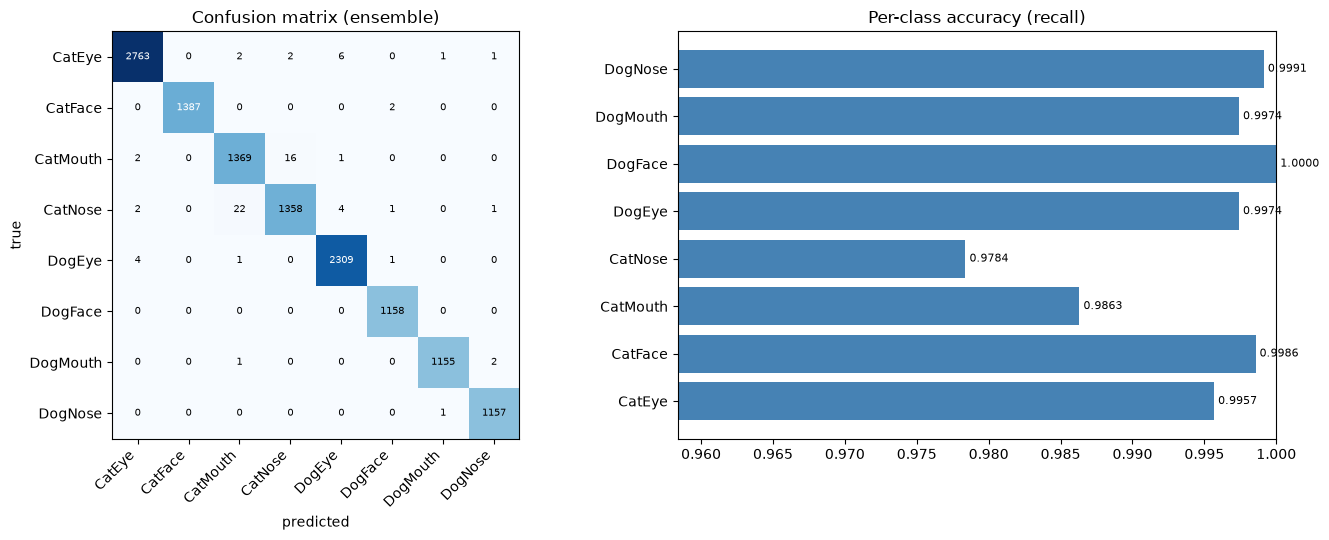

In [ ]:
# Uses classification_report to compute and print precision, recall, F1-score, and support count for every individual class
print(classification_report(y_va.numpy(), pred_val, target_names=classes, digits=4, zero_division=0))

# Computes the absolute confusion matrix and plots it as a blue-tinted heatmap
cm = confusion_matrix(y_va.numpy(), pred_val, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].imshow(cm, cmap="Blues"); ax[0].set_title(f"Confusion matrix ({FINAL})")
ax[0].set_xticks(range(NUM_CLASSES)); ax[0].set_xticklabels(classes, rotation=45, ha="right")
ax[0].set_yticks(range(NUM_CLASSES)); ax[0].set_yticklabels(classes)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
# Calculates per-class recall from the confusion matrix diagonal, plots them as blue bars, and labels each bar with its score
class_acc = cm.diagonal() / cm.sum(1)
ax[1].barh(classes, class_acc, color="steelblue")
ax[1].set_xlim(max(0, class_acc.min() - 0.02), 1.0); ax[1].set_title("Per-class accuracy (recall)")
for i, a in enumerate(class_acc):
    ax[1].text(a, i, f" {a:.4f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

73 errors out of 12729 (0.57%)
  wrong species only  :   14 (19.2%)
  wrong part only     :   50 (68.5%)
  both wrong          :    9 (12.3%)
(CatNose, CatMouth)    22
(CatMouth, CatNose)    16
(CatEye, DogEye)        6
(DogEye, CatEye)        4
(CatNose, DogEye)       4
(CatNose, CatEye)       2
(CatEye, CatMouth)      2
(CatMouth, CatEye)      2
mean confidence | correct: 0.9925 | wrong: 0.6773


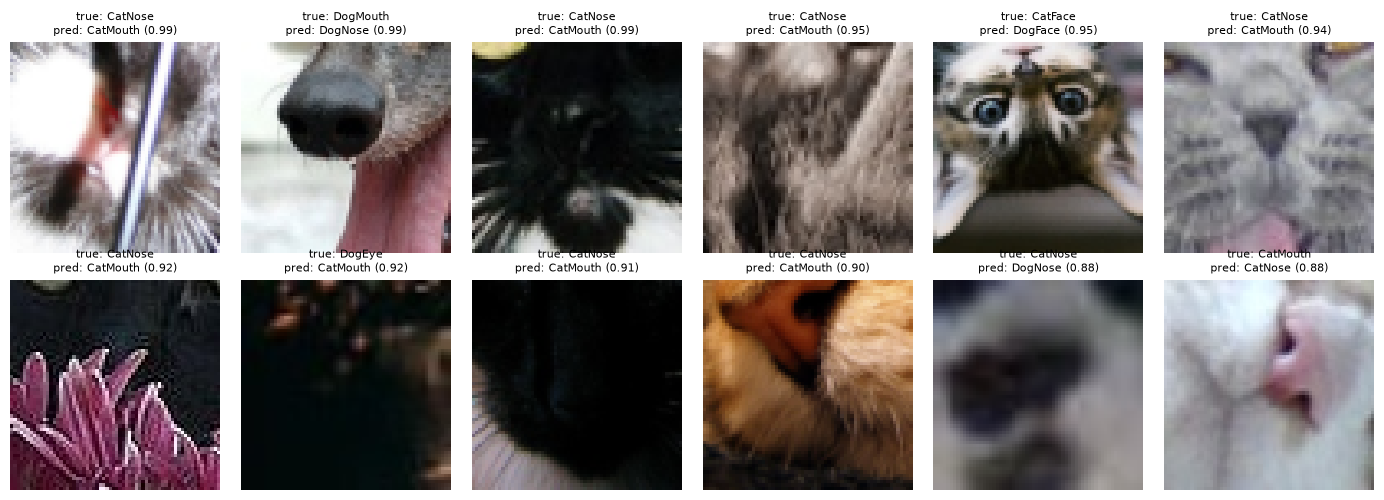

In [ ]:
# Extracts indices of all incorrect validation predictions, splits class labels into biological species, and facial anatomy
wrong = np.where(pred_val != y_va.numpy())[0]
species = lambda c: c[:3] # "Cat" or "Dog"
part = lambda c: c[3:] # "Eye", "Face", "Mouth", "Nose"
kinds = {"wrong species only": 0, "wrong part only": 0, "both wrong": 0}
for i in wrong:
    t, p = classes[y_va[i]], classes[pred_val[i]]
    same_species, same_part = species(t) == species(p), part(t) == part(p)
    kinds["wrong species only" if same_part else "wrong part only" if same_species else "both wrong"] += 1
print(f"{len(wrong)} errors out of {len(y_va)} ({len(wrong) / len(y_va):.2%})")
for k, n in kinds.items():
    print(f"  {k:20s}: {n:4d} ({n / max(len(wrong), 1):.1%})")

# The overall error rate and the 8 most frequent specific misclassifications
print(pd.Series([(classes[y_va[i]], classes[pred_val[i]]) for i in wrong]).value_counts().head(8).to_string())

# Extracts the maximum predicted probability for every sample to measure model confidence, 
# then compares the average confidence score on correct predictions against incorrect ones
conf = p_val.max(1).values
print("mean confidence | correct:", round(conf[pred_val == y_va.numpy()].mean().item(), 4),
      "| wrong:", round(conf[wrong].mean().item(), 4) if len(wrong) else None)

show = wrong[np.argsort(-conf[wrong].numpy())][:12] # the 12 most confident mistakes
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for a, i in zip(axes.ravel(), show):
    a.imshow(X_va[i].permute(1, 2, 0).numpy()); a.axis("off")
    a.set_title(f"true: {classes[y_va[i]]}\npred: {classes[pred_val[i]]} ({conf[i]:.2f})", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Checks whether the automated model selection (FINAL) chose the ensemble or an individual model
if FINAL == "ensemble":
    p_test = (get_probs("resnet18_pt", "test") + get_probs("custom_cnn", "test")) / 2
else:
    p_test = get_probs(FINAL, "test")

# Copies the original sample submission dataframe, maps the model's highest-probability index predictions back to their corresponding string class labels, and saves the result as submission.csv
submission = sub.copy() # keeps the exact ids and order of the sample file
submission["class"] = [classes[i] for i in p_test.argmax(1).tolist()]
submission.to_csv("submission.csv", index=False)

check = pd.read_csv("submission.csv", dtype=str) # re-read the saved file and verify it
assert list(check.columns) == list(sub.columns) and len(check) == len(sub)
assert check["image_id"].tolist() == sub["image_id"].tolist() and check["class"].isin(classes).all()
print("submission.csv written:", check.shape)
print(check["class"].value_counts(normalize=True).mul(100).round(1).to_string())
print(check.head().to_string())

resnet18_pt test predictions: 85s
custom_cnn test predictions: 86s
submission.csv written: (29443, 2)
class
CatEye      21.5
DogEye      18.8
CatMouth    10.8
CatFace     10.6
CatNose     10.0
DogFace      9.5
DogMouth     9.4
DogNose      9.3
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth
